In [1]:
!python predict.py demo_test_1 LLMCurators test1

img_0001.jpg -> sp-01
img_0002.jpg -> sp-01
img_0003.jpg -> sp-02
img_0004.jpg -> sp-02
img_0005.jpg -> sp-03
img_0006.jpg -> sp-03
img_0007.jpg -> sp-04
img_0008.jpg -> sp-04
img_0009.jpg -> sp-05
img_0010.jpg -> sp-05

Saved LLMCurators_test1.csv with 10 rows


In [2]:
!python predict.py demo_test_2 LLMCurators test2

img_0001.jpg -> sp-02
img_0002.jpg -> sp-02
img_0003.jpg -> sp-01
img_0004.jpg -> sp-01
img_0005.jpg -> sp-04
img_0006.jpg -> sp-04
img_0007.jpg -> sp-05
img_0008.jpg -> sp-05
img_0009.jpg -> sp-03
img_0010.jpg -> sp-03

Saved LLMCurators_test2.csv with 10 rows


In [3]:
import os
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

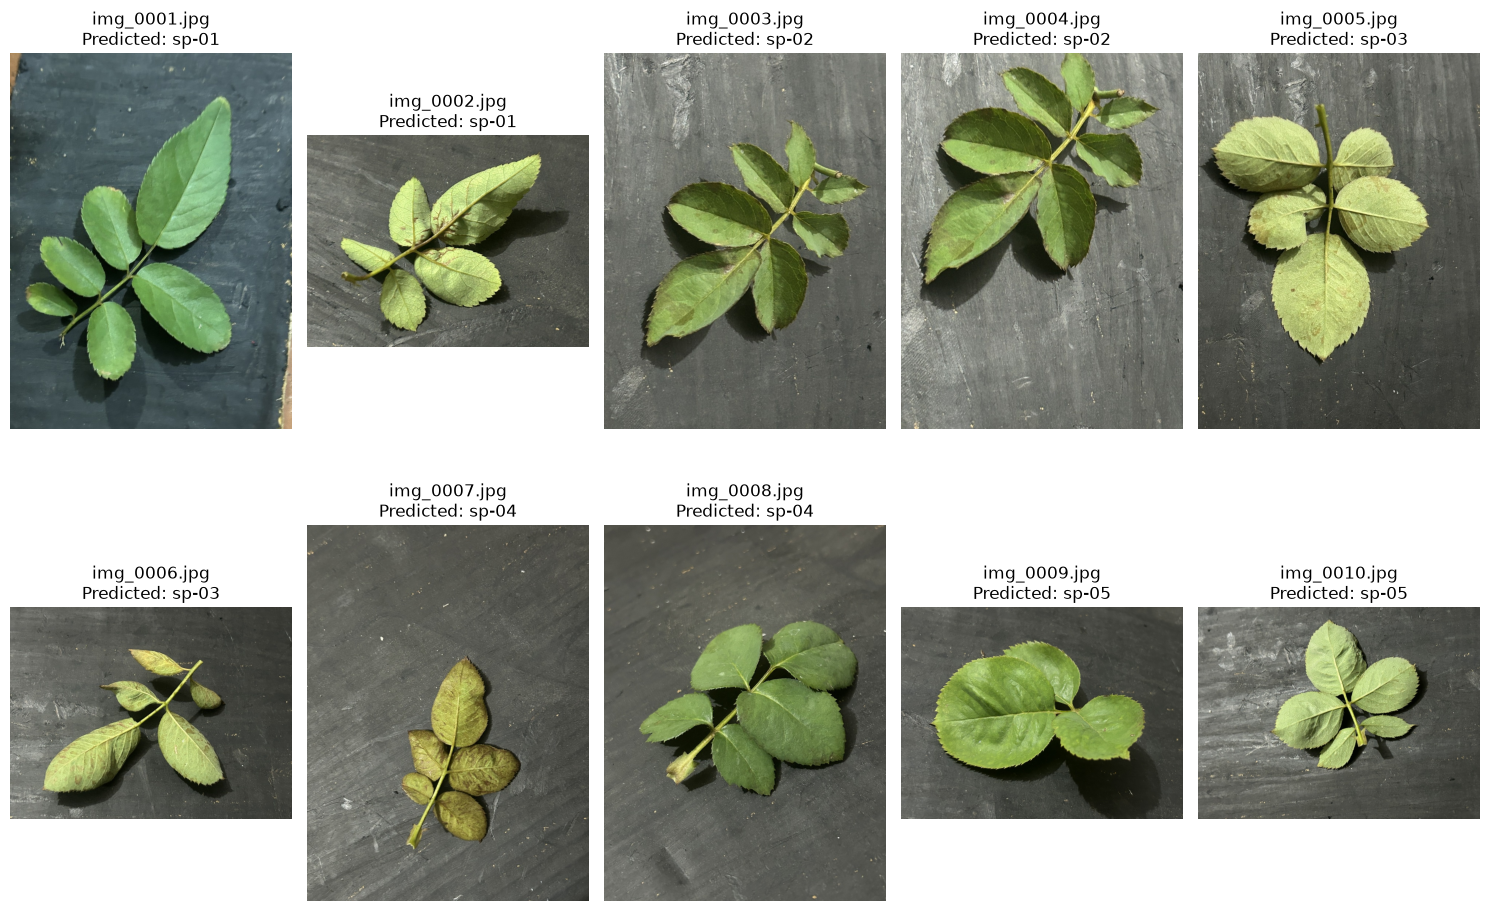

In [4]:
folder = "demo_test_1"

df = pd.read_csv("LLMCurators_prediction_test1.csv")

plt.figure(figsize=(15, 10))

for i, row in df.iterrows():

    image_path = os.path.join(folder, row["file"])

    img = Image.open(image_path).convert("RGB")

    plt.subplot(2, 5, i + 1)
    plt.imshow(img)

    plt.title(
        f'{row["file"]}\nPredicted: {row["predicted"]}'
    )

    plt.axis("off")

plt.tight_layout()
plt.show()

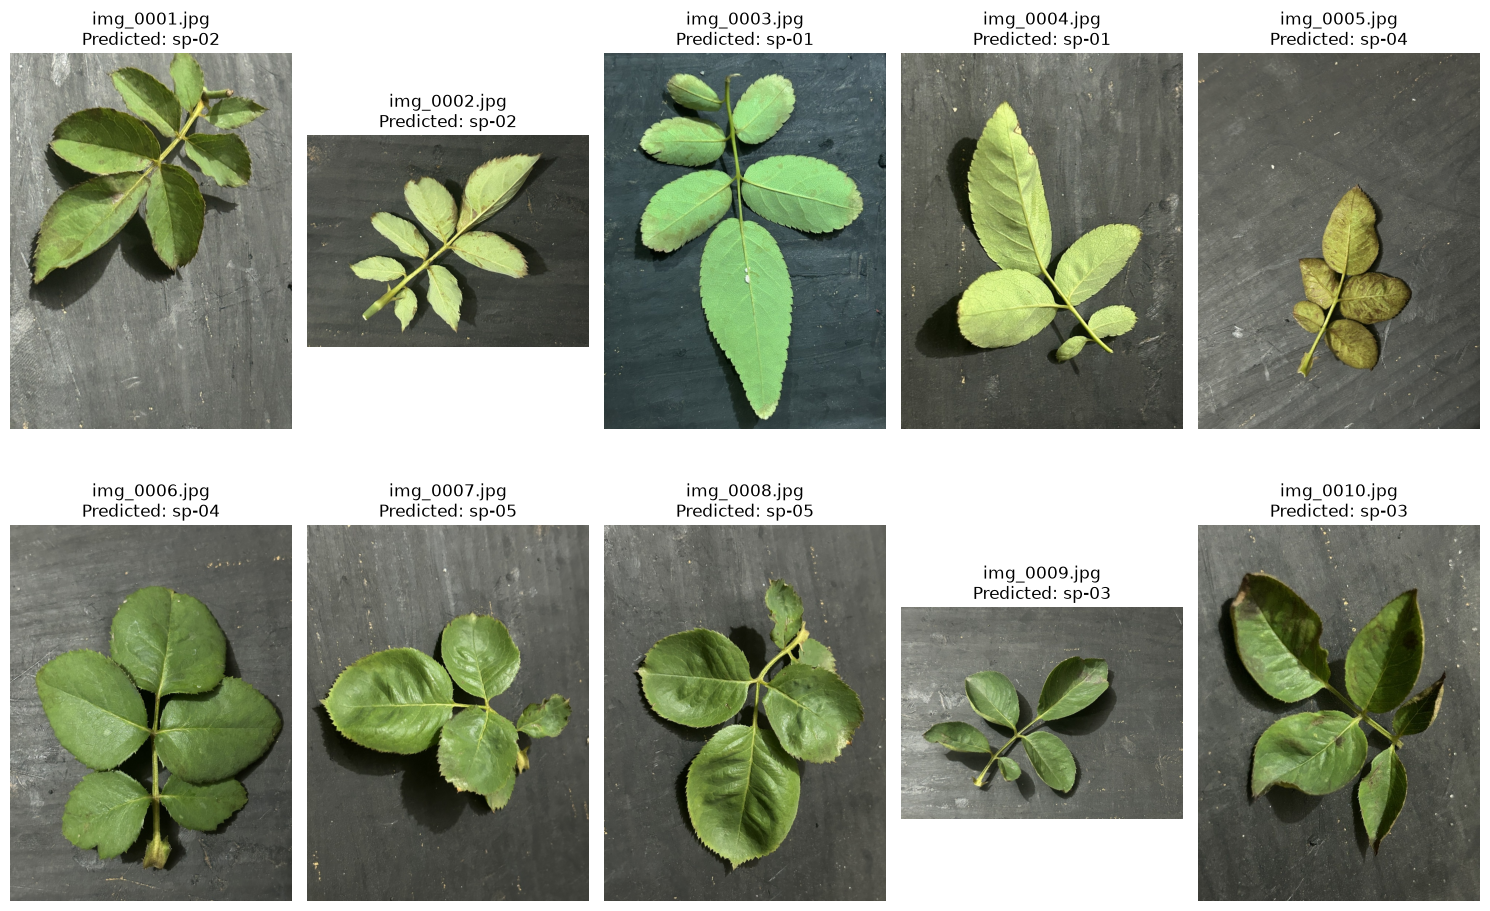

In [5]:
folder = "demo_test_2"

df = pd.read_csv("LLMCurators_prediction_test2.csv")

plt.figure(figsize=(15, 10))

for i, row in df.iterrows():

    image_path = os.path.join(folder, row["file"])

    img = Image.open(image_path).convert("RGB")

    plt.subplot(2, 5, i + 1)
    plt.imshow(img)

    plt.title(
        f'{row["file"]}\nPredicted: {row["predicted"]}'
    )

    plt.axis("off")

plt.tight_layout()
plt.show()

In [6]:
import pandas as pd

df1 = pd.read_csv("LLMCurators_prediction_test1.csv")
df2 = pd.read_csv("LLMCurators_prediction_test2.csv")

all_predictions = pd.concat([df1, df2], ignore_index=True)

print("Total images:", len(all_predictions))

print("\nSpecies prediction count:")
print(all_predictions["predicted"].value_counts())

Total images: 20

Species prediction count:
predicted
sp-01    4
sp-02    4
sp-03    4
sp-04    4
sp-05    4
Name: count, dtype: int64


In [8]:
!python check_submission.py LLMCurators_prediction_test2.csv demo_test_2 --model leaf_model.pth

file    : LLMCurators_prediction_test2.csv
team    : LLMCurators
test set: test2
columns : ['file', 'predicted']
rows    : 10
images in folder: 10
every test image has exactly one prediction

prediction counts:
predicted
sp-01    2
sp-02    2
sp-03    2
sp-04    2
sp-05    2

READY - this file is valid.


In [9]:
import hashlib, os

for path in ["model.pt", "leaf_model.pth"]:
    if os.path.exists(path):
        h = hashlib.sha256(open(path, "rb").read()).hexdigest()
        print(path, "| size MB:", round(os.path.getsize(path) / 1e6, 1), "| sha256:", h[:16])

model.pt | size MB: 44.8 | sha256: 9c04843e5310fa0d
leaf_model.pth | size MB: 44.8 | sha256: c71f81e712413081


In [11]:
!python check_submission.py LLMCurators_prediction_test2.csv demo_test_2 --model leaf_model.pth

file    : LLMCurators_prediction_test2.csv
team    : LLMCurators
test set: test2
columns : ['file', 'predicted']
rows    : 10
images in folder: 10
every test image has exactly one prediction

prediction counts:
predicted
sp-01    2
sp-02    2
sp-03    2
sp-04    2
sp-05    2

READY - this file is valid.
